In [ ]:
#details to clear up as i go

# Reproduce the paper figures

One function per figure (`make_fig_N`), each taking `fig=None, save=False` (pass a `Figure` to draw into it; `save` is `False` or an output path).
Everything is computed from the real FLASH output under `research/data/sims/`; nothing is synthesized.
Per-snapshot time series are cached to `cache/*.npz` so figures 2, 5-10 only touch the data once.

**Status:** Figs 1-7 and 9 are implemented from the equations in the paper. Figs 8, 10, 11 need inputs I could not find on disk (marked `TODO`) and raise `NotImplementedError` rather than guess.
**Not yet run** - I have not executed any of this; expect to fix field names on first run (see the field-discovery cell).

In [1]:
import os, glob
import numpy as np
import matplotlib.pyplot as plt
import yt
yt.set_log_level("error")

DATA = "/Users/thummimm/Documents/research/data/sims"
OUT = "/Users/thummimm/Documents/research/cca/outputs/figures"
CACHE = "/Users/thummimm/Documents/research/cca/data/cache"
os.makedirs(CACHE, exist_ok=True)

N_SNAP = 200            # snapshots 0000-0199 span 0-20 Myr
R_OUT_KPC = 1.0         # outflow surface radius
T_COLD, T_HOT = 1e3, 1e5   # phase boundaries [K]
FION_WARM = 0.5            # WNM / WIM split
V_ESC = 360.0              # km/s at r=1 kpc (dm + baryons) - paper Fig 5 note; recompute if desired

# label -> directory.  ASSUMPTIONS to confirm:
#   HD=NoFeedback, RHD=RHDOnly, SNe=SNeOnly, SNeRHD,f=SNeRHD, SNeRHD,Z_sun=SNeRHDZ0
#   no directory for the 0.1 Zsun run was found -> None
RUNS = {
    "HD":            dict(dir="NoFeedback", Z=0.01, color="gray",  ls=":"),
    "RHD":           dict(dir="RHDOnly",    Z=0.01, color="red",   ls=":"),
    "SNe":           dict(dir="SNeOnly",    Z=0.01, color="blue",  ls=":"),
    "SNeRHD,f":      dict(dir="SNeRHD",     Z=0.01, color="black", ls=":"),
    "SNeRHD,0.1Zsun":dict(dir=None,         Z=0.1,  color="black", ls="-."),
    "SNeRHD,Zsun":   dict(dir="SNeRHDZ0",   Z=1.0,  color="black", ls="-"),
}

In [2]:
def snap_paths(run, i):
    d = os.path.join(DATA, RUNS[run]["dir"])
    idx = f"{i:04d}"
    plt_fn = os.path.join(d, f"RHDTurb_hdf5_plt_cnt_{idx}")
    for part_fn in (os.path.join(d, f"RHDTurb_hdf5_part_{idx}"),
                    os.path.join(d, "particle_files", f"RHDTurb_hdf5_part_{idx}")):
        if os.path.exists(part_fn):
            return plt_fn, part_fn
    return plt_fn, None

HDF5_SIG = b"\x89HDF\r\n\x1a\n"

def is_valid(run, i):
    """True if the plt (and particle, if present) files exist, start with the HDF5 signature, and are actually
    allocated on disk. Some snapshots (notably SNeOnly) are missing, zero-filled, or sparse (valid header but
    almost no data written): yt either fails with 'Could not determine input format' or silently reads zeros."""
    plt_fn, part_fn = snap_paths(run, i)
    for fn in (plt_fn, part_fn):
        if fn is None:
            continue
        if not os.path.exists(fn):
            return False
        st = os.stat(fn)
        if st.st_size > 0 and st.st_blocks * 512 < 0.9 * st.st_size:   # sparse / never fully written (APFS)
            return False
        with open(fn, "rb") as fh:
            if fh.read(8) != HDF5_SIG:
                return False
    return True

def nearest_valid(run, i, max_off=20):
    """Closest usable snapshot index to i (prefers i, then i+1, i-1, ...). Prints a warning if it had to move."""
    for off in range(max_off + 1):
        for j in ((i,) if off == 0 else (i + off, i - off)):
            if 0 <= j < N_SNAP and is_valid(run, j):
                if j != i:
                    print(f"[warn] {run}: snapshot {i:04d} missing/corrupt, using {j:04d} instead")
                return j
    raise FileNotFoundError(f"{run}: no valid snapshot within {max_off} of {i}")

def load(run, i):
    if not is_valid(run, i):
        raise FileNotFoundError(f"{run} snapshot {i:04d} is missing or corrupt (bad HDF5 header); use nearest_valid()")
    plt_fn, part_fn = snap_paths(run, i)
    return yt.load(plt_fn, particle_filename=part_fn) if part_fn else yt.load(plt_fn)

def t_myr(ds):
    return float(ds.current_time.in_units("Myr"))

def savefig(fig, save):
    if save:
        fig.savefig(save, dpi=300, bbox_inches="tight")

## Field discovery
Run once on a snapshot and set `FIELD_*` below. The names here are guesses based on standard FLASH/yt conventions.

In [3]:
ds = load("SNeRHD,f", 100)
print(t_myr(ds), ds.domain_width.in_units("kpc"))
print(sorted(f for f in ds.field_list))

9.983425679577069 [2.80000263 2.80000263 2.80000263] kpc
[('all', 'particle_accr_rate'), ('all', 'particle_accx'), ('all', 'particle_accy'), ('all', 'particle_accz'), ('all', 'particle_age'), ('all', 'particle_blk'), ('all', 'particle_burn_state'), ('all', 'particle_creation_time'), ('all', 'particle_deuterium_mass'), ('all', 'particle_dtold'), ('all', 'particle_lumeuv'), ('all', 'particle_luminosity'), ('all', 'particle_lumlw'), ('all', 'particle_lumpe'), ('all', 'particle_mass'), ('all', 'particle_oacx'), ('all', 'particle_oacy'), ('all', 'particle_oacz'), ('all', 'particle_old_pmass'), ('all', 'particle_posx'), ('all', 'particle_posy'), ('all', 'particle_posz'), ('all', 'particle_proc'), ('all', 'particle_ssne'), ('all', 'particle_stellar_radius'), ('all', 'particle_tag'), ('all', 'particle_velx'), ('all', 'particle_vely'), ('all', 'particle_velz'), ('all', 'particle_x_ang'), ('all', 'particle_x_ang_old'), ('all', 'particle_y_ang'), ('all', 'particle_y_ang_old'), ('all', 'particle_z

In [4]:
FIELD_IONFRAC = ("flash", "hp  ")   # TODO confirm: H+ mass fraction field (f_ion). Used for WNM/WIM split.
FIELD_TEMP    = ("gas", "temperature")
FIELD_DENS    = ("gas", "density")
FIELD_NUM     = ("gas", "number_density")  # n in cm^-3 for Fig 3

## Fig 1 / Fig 4 - surface-density snapshots

> **Data note (Fig 4):** `SNeOnly/RHDTurb_hdf5_plt_cnt_0150` is corrupted/incomplete (zero bytes on disk), so the SNe panel uses the next snapshot, `RHDTurb_hdf5_plt_cnt_0151`. All four panels are still labeled t = 15.0 Myr; `make_fig_4` prints each panel's actual time when it runs. Mention this in the Fig 4 caption.

In [5]:
from mpl_toolkits.axes_grid1 import AxesGrid
from yt.utilities.exceptions import YTFieldNotFound

def make_snapshot(run, i, width_kpc=2.8, label=None, tlabel=None):
    """yt ProjectionPlot of Sigma with the same annotations as make_fid_Sigma_movie.ipynb.
    label=None -> timestamp (t = X Myr); otherwise the given text (e.g. the run name).
    tlabel: if given, drawn under the label instead of the true time (see the note on Fig 4)."""
    ds = load(run, i)
    p = yt.ProjectionPlot(ds, "z", FIELD_DENS, width=(width_kpc, "kpc"))
    p.set_unit(FIELD_DENS, "Msun/pc**2"); p.set_zlim(FIELD_DENS, 1e1, 1e5)
    p.set_cmap(FIELD_DENS, "magma"); p.set_buff_size(1024)
    p.hide_axes()
    # factor = pixels per arrow (1024 px buffer: 32 -> ~32 arrows per side, was 16 -> 64); width/head* set arrow size
    p.annotate_velocity(factor=32, color="k", headwidth=4, headlength=5, headaxislength=4.5, width=0.003)
    try:
        has_particles = ds.all_data()["nbody", "particle_position_x"].size > 0
    except YTFieldNotFound:
        has_particles = False
    if has_particles:
        p.annotate_particles((width_kpc, "kpc"), p_size=80, col="white", marker="*", ptype="nbody")
    if label is None:
        p.annotate_timestamp(corner="upper_left", text_args={"color": "white"})
    else:
        p.annotate_text((0.04, 0.94), label, coord_system="axis", text_args={"color": "white"})
    if tlabel is not None:
        p.annotate_text((0.04, 0.87), tlabel, coord_system="axis", text_args={"color": "white"})
    p.annotate_scale(corner="upper_right", size_bar_args={"color": "white"})
    p._ds_keepalive = ds   # yt only weakly references ds; without this it is garbage-collected before _grid renders
    return p

def _grid(plots, fig=None, figsize=(8, 8)):
    """Tile yt plots into one matplotlib figure (yt multi-panel cookbook pattern: hand each plot an AxesGrid axes)."""
    fig = fig or plt.figure(figsize=figsize)
    grid = AxesGrid(fig, (0.05, 0.05, 0.9, 0.9), nrows_ncols=(2, 2), axes_pad=0.05, label_mode="1",
                    share_all=True, cbar_location="bottom", cbar_mode="single", cbar_size="3%", cbar_pad="2%")
    for k, p in enumerate(plots):
        pl = p.plots[FIELD_DENS]
        pl.figure, pl.axes, pl.cax = fig, grid[k].axes, grid.cbar_axes[0]
        p._setup_plots()
    grid.cbar_axes[0].set_xlabel(r"$\Sigma\ [M_\odot\,{\rm pc}^{-2}]$")
    return fig

def make_fig_1(run="SNeRHD,f", snaps=(50, 100, 150, 199), fig=None, save=False):
    fig = _grid([make_snapshot(run, nearest_valid(run, i)) for i in snaps], fig)
    savefig(fig, save); return fig

def make_fig_4(snap=150, tlabel="t = 15.0 Myr", fig=None, save=False):
    # NOTE: SNeOnly plt_cnt_0150 is corrupted/incomplete (see Data note above), so nearest_valid() uses 0151 for
    # that panel. The panels are all labeled tlabel (15.0 Myr) by choice; the SNe panel is really snapshot 0151.
    plots = [make_snapshot(r, nearest_valid(r, snap), label=r, tlabel=tlabel) for r in ["HD", "RHD", "SNe", "SNeRHD,f"]]
    for r, p in zip(["HD", "RHD", "SNe", "SNeRHD,f"], plots):
        print(f"Fig 4 {r}: actual t = {t_myr(p._ds_keepalive):.2f} Myr (labeled {tlabel})")
    fig = _grid(plots, fig)
    savefig(fig, save); return fig


## Time series (cached)
For each run and snapshot: `t`, stellar mass, and outflow quantities through a shell at r = 1 kpc.
Outflow fluxes use a thin-shell estimate of the surface integrals in Eqs. 21-23:
$\dot M = \sum \rho\, v_r H(v_r)\, dV / (2\,\delta r)$, with the shell $|r - r_0| < \delta r$ (AMR cells, so `dV` is exact).
Phases are split by T and f_ion as in Sec 3.4.

In [6]:
PHASES = ["CNM", "WNM", "WIM", "HIM"]
def phase_masks(T, fion):
    return dict(CNM=T < T_COLD,
                WNM=(T >= T_COLD) & (T < T_HOT) & (fion < FION_WARM),
                WIM=(T >= T_COLD) & (T < T_HOT) & (fion >= FION_WARM),
                HIM=T >= T_HOT)

In [7]:
def snapshot_quantities(run, i, r0_kpc=R_OUT_KPC, dr_kpc=0.05):
    ds = load(run, i)
    sph = ds.sphere(ds.domain_center, (r0_kpc + dr_kpc, "kpc"))   # sphere sets center for radius / radial_velocity
    shell = sph["index", "radius"].to("kpc").v > r0_kpc - dr_kpc
    g = lambda f, u: sph[f].to(u).v[shell]
    rho = g(FIELD_DENS, "Msun/pc**3")
    dV = g(("gas", "cell_volume"), "pc**3")
    vr = g(("gas", "radial_velocity"), "km/s")
    T = g(FIELD_TEMP, "K")
    fion = sph[FIELD_IONFRAC].v[shell]
    e_int = (g(("gas", "specific_thermal_energy"), "km**2/s**2")
             if ("gas", "specific_thermal_energy") in ds.derived_field_list else 0.0 * vr)
    dr_pc = 2 * dr_kpc * 1e3
    out = vr > 0
    v2 = g(("gas", "velocity_magnitude"), "km/s") ** 2
    w = {}
    for name, m in dict(All=np.ones_like(T, bool), **phase_masks(T, fion)).items():
        k = m & out
        mdot = np.sum(rho[k] * vr[k] * dV[k]) / dr_pc                       # Msun/pc * km/s
        pdot = np.sum(rho[k] * vr[k] ** 2 * dV[k]) / dr_pc
        edot = np.sum(rho[k] * vr[k] * (0.5 * v2[k] + e_int[k]) * dV[k]) / dr_pc
        vavg = (np.sum(rho[k] * vr[k] ** 2 * dV[k]) / np.sum(rho[k] * vr[k] * dV[k])) if k.any() else np.nan
        w[name] = (mdot, pdot, edot, vavg)
    # Msun/pc * km/s -> Msun/Myr via 1 km/s = 1.0227 pc/Myr; Msun (km/s)^2 -> erg via 1.989e33 g * 1e10 cm^2/s^2
    PCMYR, MSUN_KMS2_ERG = 1.0227, 1.989e43
    res = {n: (v[0] * PCMYR, v[1] * PCMYR, v[2] * PCMYR * MSUN_KMS2_ERG, v[3]) for n, v in w.items()}
    ad = ds.all_data()
    try:
        mstar = float(ad["nbody", "particle_mass"].to("Msun").sum())
    except Exception:
        mstar = 0.0
    return t_myr(ds), mstar, res

> Sanity-check on the first run against Fig 5: Mdot ~ 3e8 Msun/Myr, Edot ~ 1e57-1e58 erg/Myr, <v> ~ 1000 km/s after ~7 Myr.

In [8]:
def get_series(run, force=False):
    fn = os.path.join(CACHE, f"series_{run.replace(',', '_')}.npz")
    if os.path.exists(fn) and not force:
        return dict(np.load(fn, allow_pickle=True))
    t, ms, q = [], [], {p: [] for p in ["All"] + PHASES}
    skipped = [i for i in range(N_SNAP) if not is_valid(run, i)]
    if skipped:
        print(f"[warn] {run}: skipping {len(skipped)} missing/corrupt snapshots")
    for i in range(N_SNAP):
        if i in skipped:
            continue
        ti, mi, r = snapshot_quantities(run, i)
        t.append(ti); ms.append(mi)
        for p in q: q[p].append(r[p])
    out = dict(t=np.array(t), mstar=np.array(ms), **{p: np.array(v) for p, v in q.items()})
    np.savez(fn, **out); return out

## Fig 2 - star formation efficiency

In [9]:
def make_fig_2(runs=("HD", "RHD", "SNe", "SNeRHD,f", "SNeRHD,0.1Zsun", "SNeRHD,Zsun"), fig=None, save=False):
    fig = fig or plt.figure(figsize=(5, 4)); ax = fig.add_subplot()
    M0 = float(load("SNeRHD,f", 0).all_data()["gas", "mass"].to("Msun").sum())
    for r in runs:
        if RUNS[r]["dir"] is None: continue
        s = get_series(r)
        ax.plot(s["t"], s["mstar"] / 1e10, color=RUNS[r]["color"], ls=RUNS[r]["ls"], label=r)
    ax.set(xlabel="t [Myr]", ylabel=r"$M_*\ [10^{10}\,M_\odot]$", xlim=(0, 20), ylim=0)
    ax2 = ax.secondary_yaxis("right", functions=(lambda y: y * 1e10 / M0, lambda y: y * M0 / 1e10))
    ax2.set_ylabel(r"SFE $=M_*/M_{\rm gas,0}$")
    ax.legend(); savefig(fig, save); return fig

## Fig 3 - phase diagrams at 10 Myr

In [10]:
def make_fig_3(snap=100, fig=None, save=False):
    fig = fig or plt.figure(figsize=(9, 6)); axs = fig.subplots(2, 3, sharex=True, sharey=True).ravel()
    for ax, r in zip(axs, RUNS):
        ax.set_title(r)
        if RUNS[r]["dir"] is None: continue
        ad = load(r, snap).all_data()
        n = ad[FIELD_NUM].to("cm**-3").v; T = ad[FIELD_TEMP].to("K").v; f = ad[FIELD_IONFRAC].v
        sel = np.random.default_rng(0).choice(n.size, min(5000, n.size), replace=False)
        sc = ax.scatter(n[sel], T[sel], c=np.clip(f[sel], 1e-2, 1), s=1, cmap="coolwarm_r",
                        norm=plt.matplotlib.colors.LogNorm(1e-2, 1))
        ax.set(xscale="log", yscale="log")
        for T0 in (T_COLD, T_HOT): ax.axhline(T0, color="k", ls="--", lw=1)
    fig.supxlabel(r"$n\ [{\rm cm^{-3}}]$"); fig.supylabel("T [K]")
    fig.colorbar(sc, ax=axs, label=r"$f_{\rm ion}$", shrink=0.6); savefig(fig, save); return fig

## Figs 5-7 - outflow rates, velocities, and metallicity dependence

In [11]:
def make_fig_5(run="SNeRHD,f", fig=None, save=False):
    s = get_series(run)
    fig = fig or plt.figure(figsize=(12, 3)); axs = fig.subplots(1, 4)
    names = [r"$\langle v_{\rm out}\rangle$ [km/s]", r"$\dot M_{\rm out}$", r"$\dot p_{\rm out}$", r"$\dot E_{\rm out}$"]
    for k, (ax, nm) in enumerate(zip(axs, names)):
        ax.plot(s["t"], [row[{0: 3, 1: 0, 2: 1, 3: 2}[k]] for row in s["All"]], "k"); ax.set_title(nm)
        ax.set_xlabel("t [Myr]")
        if k: ax.set_yscale("log")
    axs[0].axhline(V_ESC, color="gray"); 
    # TODO: overlay analytic per-SN yields (grey lines): Mdot_SNe, p_SNe = 2.8e5 (n/n0)^-1/7 (Z/Z0)^-2/7 Msun km/s * Rate_SNe, E_SNe = N_SNe*1e51 erg
    savefig(fig, save); return fig

def _bulk(run, t0, t1=20.0):
    s = get_series(run); m = (s["t"] >= t0) & (s["t"] <= t1)
    res = {}
    for ph in ["All"] + PHASES:
        a = s[ph][m]
        res[ph] = dict(v=np.nanmean(a[:, 3]), vsig=np.nanstd(a[:, 3]),
                       M=np.trapz(a[:, 0], s["t"][m]), p=np.trapz(a[:, 1], s["t"][m]), E=np.trapz(a[:, 2], s["t"][m]))
    return res

def _bulk_fig(rows, xlabels, t0, fig, save):
    fig = fig or plt.figure(figsize=(12, 3)); axs = fig.subplots(1, 4)
    cols = dict(All="k", HIM="hotpink", WIM="g", WNM="g", CNM="cornflowerblue")
    for x, r in enumerate(rows):
        b = _bulk(r, t0)
        for ph in ["All"] + PHASES:
            for ax, key in zip(axs, "v M p E".split()):
                ax.errorbar(x, b[ph][key], yerr=b[ph]["vsig"] if key == "v" else None, fmt="o",
                            color=cols[ph], mfc="none" if ph == "WIM" else cols[ph])
    for ax in axs[1:]: ax.set_yscale("log")
    for ax in axs: ax.set_xticks(range(len(rows))); ax.set_xticklabels(xlabels, rotation=30)
    savefig(fig, save); return fig

def make_fig_6(t0=6.7, fig=None, save=False):
    # NOTE: your note says the paper averages from 8 Myr; t0 here is the launch time (first SN) - set to the intended value.
    return _bulk_fig(["HD", "RHD", "SNe", "SNeRHD,f"], ["HD", "RHD", "SNe", "SNeRHD"], t0, fig, save)

def make_fig_7(t0=6.7, fig=None, save=False):
    rows = [r for r in ["SNeRHD,f", "SNeRHD,0.1Zsun", "SNeRHD,Zsun"] if RUNS[r]["dir"]]
    return _bulk_fig(rows, [r"$10^{-2}$", r"$10^{-1}$", "1"][:len(rows)], t0, fig, save)

## Fig 9 - energy distribution by phase vs radius

In [12]:
def make_fig_9(run="SNeRHD,f", t_range=(6.7, 20.0), nbins=24, fig=None, save=False):
    """Median and 1-sigma of e_tot = v^2/2 + e_int + phi over radial bins, per phase. phi is NOT included here (TODO) - that's why v_crit is not drawn."""
    fig = fig or plt.figure(figsize=(6, 5)); ax = fig.add_subplot()
    edges = np.logspace(np.log10(0.3), np.log10(100), nbins + 1)   # kpc
    acc = {ph: [[] for _ in range(nbins)] for ph in ["WNM", "WIM", "HIM"]}
    for i in range(N_SNAP):
        if not is_valid(run, i):
            continue
        ds = load(run, i)
        if not (t_range[0] <= t_myr(ds) <= t_range[1]): continue
        ad = ds.all_data(); ad.set_field_parameter("center", ds.domain_center)
        r = ad["index", "radius"].to("kpc").v; T = ad[FIELD_TEMP].to("K").v; f = ad[FIELD_IONFRAC].v
        e = 0.5 * ad["gas", "velocity_magnitude"].to("km/s").v ** 2        # TODO + e_int + phi
        pm = phase_masks(T, f); b = np.digitize(r, edges) - 1
        for ph in acc:
            for k in range(nbins):
                sel = pm[ph] & (b == k)
                if sel.any(): acc[ph][k].append(np.median(e[sel]))
    rc = np.sqrt(edges[1:] * edges[:-1])
    for ph, c in dict(WNM="g", WIM="g", HIM="hotpink").items():
        med = np.array([np.median(a) if a else np.nan for a in acc[ph]])
        ax.plot(rc, med, color=c, ls="--" if ph == "WIM" else "-", label=ph)
    ax.set(xscale="log", yscale="log", xlabel="R [kpc]", ylabel=r"$e_{\rm tot}$ [km$^2$/s$^2$]"); ax.legend()
    savefig(fig, save); return fig

## Figs 8, 10, 11 - need inputs I could not locate
- **Fig 8** (f_esc in EUV/LW/PE): needs per-band stellar luminosities and the dust+gas absorption rates (Eq 25). Possibly derivable from the `*_SolidAngleData.npy` files or the raytrace logs, but I don't know their schema.
- **Fig 10** (A_V, M_UV): needs the dust model/opacity you used and a stellar-population luminosity model.
- **Fig 11** (resolution): needs the 256³ runs, which I did not find under `data/sims/`.

In [13]:
def make_fig_8(*a, **k):  raise NotImplementedError("TODO: f_esc needs band luminosities + absorption rates; see markdown above")
def make_fig_10(*a, **k): raise NotImplementedError("TODO: A_V / M_UV need dust opacity + stellar luminosity model")
def make_fig_11(*a, **k): raise NotImplementedError("TODO: 256^3 runs not found under data/sims")

## Build the figures
One cell per figure; each saves to `paper_figs/figN.png` and shows the result. Run them independently.

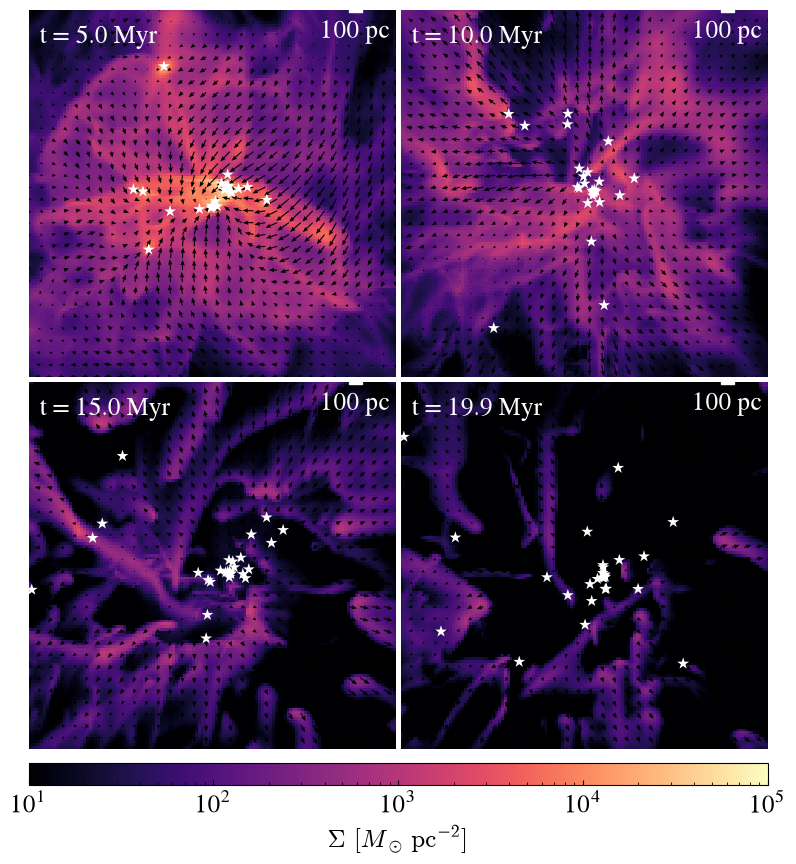

In [14]:
# Fig 1 - fiducial Sigma snapshots (5, 10, 15, 20 Myr)
fig = make_fig_1(save=os.path.join(OUT, "fig1.png"))
plt.show()

KeyboardInterrupt: 

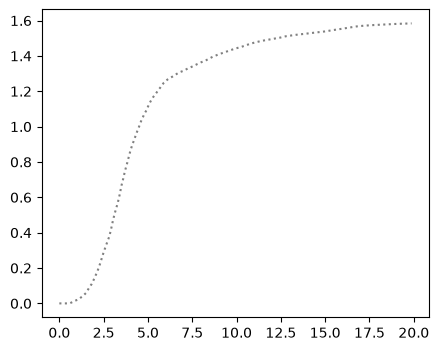

In [15]:
# Fig 2 - star formation efficiency
fig = make_fig_2(save=os.path.join(OUT, "fig2.png"))
plt.show()

In [ ]:
# Fig 3 - phase diagrams at 10 Myr
fig = make_fig_3(save=os.path.join(OUT, "fig3.png"))
plt.show()

In [ ]:
# Fig 4 - Sigma at 15 Myr for the four feedback cases (SNe panel uses snapshot 0151, see data note)
fig = make_fig_4(save=os.path.join(OUT, "fig4.png"))
plt.show()

In [ ]:
# Fig 5 - outflow rates and velocity, fiducial run
fig = make_fig_5(save=os.path.join(OUT, "fig5.png"))
plt.show()

In [ ]:
# Fig 6 - outflow properties by phase and feedback case
fig = make_fig_6(save=os.path.join(OUT, "fig6.png"))
plt.show()

In [ ]:
# Fig 7 - outflow properties vs metallicity
fig = make_fig_7(save=os.path.join(OUT, "fig7.png"))
plt.show()

In [ ]:
# Fig 9 - energy distribution by phase vs radius
fig = make_fig_9(save=os.path.join(OUT, "fig9.png"))
plt.show()

In [ ]:
# Fig 8 - photon escape fractions - NOT IMPLEMENTED yet (see markdown above); uncomment once make_fig_8 exists
# fig = make_fig_8(save=os.path.join(OUT, "fig8.png"))
# plt.show()

In [ ]:
# Fig 10 - A_V and M_UV - NOT IMPLEMENTED yet (see markdown above); uncomment once make_fig_10 exists
# fig = make_fig_10(save=os.path.join(OUT, "fig10.png"))
# plt.show()

In [ ]:
# Fig 11 - resolution test - NOT IMPLEMENTED yet (see markdown above); uncomment once make_fig_11 exists
# fig = make_fig_11(save=os.path.join(OUT, "fig11.png"))
# plt.show()